# 02 — Exploratory Data Analysis with a categorical label

## A label-aware EDA for tabular data

This notebook implements the workflow described in `docs/exploratory_data_analysis_categorical_labels.md` using the **processed synthetic Alzheimer dataset** produced by notebook `01_tabular_data_preprocessing.ipynb`.

The purpose is to study the dataset systematically before any predictive modelling. The analysis is organized from simple to complex:

1. dataset-level structure;
2. class balance;
3. univariate numerical analysis conditioned on the label;
4. categorical prevalence conditioned on the label;
5. label-specific outlier diagnostics;
6. statistical comparison between label groups;
7. bivariate relationships;
8. label-specific correlation structure;
9. PCA;
10. nonlinear projections.

Throughout the notebook, the categorical target is used to **compare and visualize groups**, but it is never inserted as an input feature into unsupervised projections.

> **Important:** this is a synthetic educational dataset. The notebook demonstrates analytical methodology. It does not establish clinical associations, diagnostic rules, causal relationships, or predictive performance.

## Learning objectives

After completing this notebook, students should be able to:

- distinguish structural summaries from statistical comparisons;
- summarize numerical and categorical variables **by class**;
- visualize distributions without relying on a single statistic;
- identify potential outliers within each label group;
- choose statistical tests according to variable type;
- complement p-values with effect sizes and multiple-testing correction;
- compare correlation structures between groups;
- understand what PCA, t-SNE, and UMAP do and do not show;
- export tables and figures reproducibly.

This notebook is intentionally **not a modelling notebook**. It does not perform train/test splitting, feature selection for a predictive model, hyperparameter optimization, or model evaluation.

## 1. Imports and reproducibility

The core analysis uses:

- `pandas` and `numpy` for tabular manipulation;
- `seaborn` and `matplotlib` for visualization;
- `scipy` for statistical tests;
- `statsmodels` for false-discovery-rate correction;
- `scikit-learn` for scaling, PCA, and t-SNE.

UMAP is demonstrated when `umap-learn` is installed. The notebook remains executable without it.

A fixed random seed is used for stochastic projections so that repeated executions are comparable.

In [14]:
from pathlib import Path
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.multitest import multipletests

from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")

# Soft palettes keep heatmaps readable without overwhelming the data.
PASTEL_SEQUENTIAL_CMAP = sns.light_palette(
    "#7A9EBA",
    n_colors=256,
    as_cmap=True,
)
PASTEL_DIVERGING_CMAP = sns.diverging_palette(
    260,
    145,
    s=45,
    l=75,
    center="light",
    as_cmap=True,
)

try:
    import umap.umap_ as umap
    UMAP_AVAILABLE = True
except ImportError:
    UMAP_AVAILABLE = False

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("seaborn:", sns.__version__)
print("UMAP available:", UMAP_AVAILABLE)

Python: 3.14.8
pandas: 3.0.6
seaborn: 0.13.2
UMAP available: True


## 2. Project paths

The notebook locates the repository root dynamically instead of using a machine-specific absolute path.

All EDA outputs are written under:

```text
results/synthetic_alzheimer/eda_categorical/
├── figures/
└── tables/
```

The original processed dataset is never overwritten.

In [15]:
def find_project_root(start: Path) -> Path:
    start = start.resolve()

    for candidate in [start, *start.parents]:
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate

    raise FileNotFoundError(
        "Could not locate the repository root. Run the notebook from inside the project."
    )


PROJECT_ROOT = find_project_root(Path.cwd())

PROCESSED_DIR = PROJECT_ROOT / "data" / "synthetic_alzheimer" / "processed_data"
PROCESSED_DATA_PATH = PROCESSED_DIR / "synthetic_alzheimer_patients_1000_processed.csv"
PREPROCESSING_REPORT_PATH = PROCESSED_DIR / "preprocessing_report.json"

RESULTS_DIR = PROJECT_ROOT / "results" / "synthetic_alzheimer" / "eda_categorical"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

print("Processed data:", PROCESSED_DATA_PATH.relative_to(PROJECT_ROOT))
print("EDA results:", RESULTS_DIR.relative_to(PROJECT_ROOT))

Processed data: data/synthetic_alzheimer/processed_data/synthetic_alzheimer_patients_1000_processed.csv
EDA results: results/synthetic_alzheimer/eda_categorical


## 3. Load the processed dataset and its preprocessing report

The preprocessing report already contains the normalized analytical roles of the columns. Reusing it avoids guessing whether a `0/1` column should be interpreted as numerical or categorical.

The EDA therefore starts from the **processed dataset**, not from the raw source.

In [16]:
if not PROCESSED_DATA_PATH.exists():
    raise FileNotFoundError(
        "Processed data were not found. Run 01_tabular_data_preprocessing.ipynb first."
    )

if not PREPROCESSING_REPORT_PATH.exists():
    raise FileNotFoundError(
        "The preprocessing report was not found. Run 01_tabular_data_preprocessing.ipynb first."
    )

df = pd.read_csv(PROCESSED_DATA_PATH)

with PREPROCESSING_REPORT_PATH.open("r", encoding="utf-8") as file:
    preprocessing_report = json.load(file)

ID_COLUMN = preprocessing_report["identifier_column"]
TARGET_COLUMN = preprocessing_report["target_column"]
NUMERICAL_COLUMNS = list(preprocessing_report["numerical_columns"])
CATEGORICAL_COLUMNS = list(preprocessing_report["categorical_columns"])

expected_columns = {
    ID_COLUMN,
    TARGET_COLUMN,
    *NUMERICAL_COLUMNS,
    *CATEGORICAL_COLUMNS,
}
missing_columns = sorted(expected_columns - set(df.columns))

if missing_columns:
    raise ValueError(f"Processed dataset is missing expected columns: {missing_columns}")

print("Shape:", df.shape)
print("Identifier:", ID_COLUMN)
print("Target:", TARGET_COLUMN)
print("Numerical features:", len(NUMERICAL_COLUMNS))
print("Categorical features:", len(CATEGORICAL_COLUMNS))

Shape: (1000, 31)
Identifier: patient_id
Target: alzheimer
Numerical features: 10
Categorical features: 19


## 4. Make the label human-readable

The source target is encoded as `0/1`. For figures, readable class names are preferable to unexplained integers.

We create a temporary display column called `label_name`. This column is used only for visualization and summaries. It is **not exported back into the processed dataset**.

In [17]:
target_values = sorted(df[TARGET_COLUMN].dropna().unique().tolist())

if target_values != [0, 1]:
    raise ValueError(
        "This teaching notebook expects a binary target encoded as 0 and 1. "
        f"Observed values: {target_values}"
    )

LABEL_NAMES = {
    0: "No Alzheimer",
    1: "Alzheimer",
}
LABEL_ORDER = [LABEL_NAMES[value] for value in target_values]

eda_df = df.copy()
eda_df["label_name"] = eda_df[TARGET_COLUMN].map(LABEL_NAMES)

display(eda_df[[ID_COLUMN, TARGET_COLUMN, "label_name"]].head())

,patient_id,alzheimer,label_name
0,P0001,1,Alzheimer
1,P0002,1,Alzheimer
2,P0003,1,Alzheimer
3,P0004,1,Alzheimer
4,P0005,0,No Alzheimer


# Part I — Dataset-level summary

## 5. Structural profile

Before testing hypotheses or interpreting plots, record what the dataset contains.

This first table summarizes:

- observations and variables;
- analytical roles;
- classes;
- missing cells;
- duplicate rows;
- duplicated identifiers.

These values describe the **structure of the analytical object**. They are not yet scientific conclusions.

In [18]:
dataset_summary = pd.DataFrame(
    {
        "property": [
            "Observations",
            "Columns in processed table",
            "Identifier columns",
            "Numerical features",
            "Categorical features",
            "Target columns",
            "Target classes",
            "Missing cells",
            "Exact duplicate rows",
            "Duplicated identifiers",
        ],
        "value": [
            len(df),
            df.shape[1],
            1,
            len(NUMERICAL_COLUMNS),
            len(CATEGORICAL_COLUMNS),
            1,
            df[TARGET_COLUMN].nunique(),
            int(df.isna().sum().sum()),
            int(df.duplicated().sum()),
            int(df[ID_COLUMN].duplicated().sum()),
        ],
    }
)

dataset_summary.to_csv(TABLES_DIR / "dataset_summary.csv", index=False)
display(dataset_summary)

,property,value
0,Observations,1000
1,Columns in processed table,31
2,Identifier columns,1
3,Numerical features,10
4,Categorical features,19
5,Target columns,1
6,Target classes,2
7,Missing cells,0
8,Exact duplicate rows,0
9,Duplicated identifiers,0


## 6. Class balance

With a categorical label, class composition is one of the first quantities to inspect.

A class imbalance does not automatically make a dataset unusable, but it affects:

- how summary statistics should be interpreted;
- how later data splitting should be performed;
- which predictive metrics will be appropriate;
- whether apparently strong global patterns are dominated by the majority class.

We therefore report both **counts and proportions**.

In [19]:
class_summary = (
    eda_df.groupby([TARGET_COLUMN, "label_name"], observed=True)
    .size()
    .rename("count")
    .reset_index()
)

class_summary["proportion"] = class_summary["count"] / len(eda_df)
class_summary["percentage"] = 100 * class_summary["proportion"]

class_summary.to_csv(TABLES_DIR / "class_summary.csv", index=False)
display(class_summary)

,alzheimer,label_name,count,proportion,percentage
0,0,No Alzheimer,657,0.657,65.7
1,1,Alzheimer,343,0.343,34.3


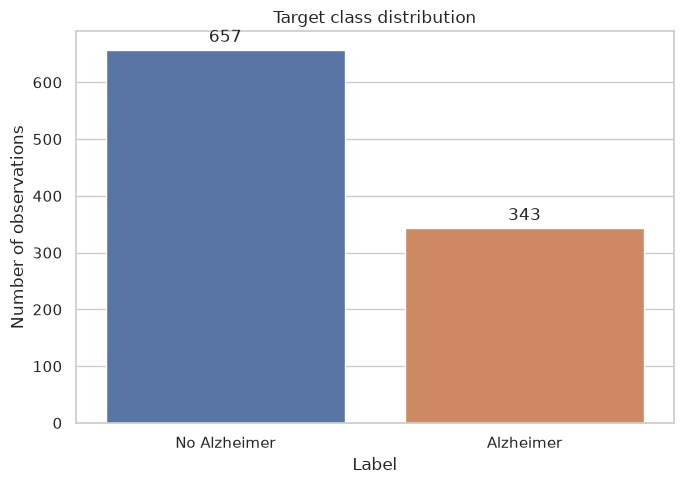

In [20]:
fig, ax = plt.subplots(figsize=(7, 5))

sns.countplot(
    data=eda_df,
    x="label_name",
    hue="label_name",
    order=LABEL_ORDER,
    hue_order=LABEL_ORDER,
    legend=False,
    ax=ax,
)

ax.set(
    title="Target class distribution",
    xlabel="Label",
    ylabel="Number of observations",
)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_class_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

## 7. Missingness by label

Missingness can itself have structure. A variable may look complete overall while one class contains more missing measurements than another.

For that reason, missingness should be summarized **within each label group**, not only globally.

The current processed dataset contains no missing values, but the code below is written so that the same notebook remains informative if a later version does.

In [21]:
missingness_records = []

for target_value, label_name in LABEL_NAMES.items():
    subset = eda_df.loc[eda_df[TARGET_COLUMN] == target_value]

    for column in NUMERICAL_COLUMNS + CATEGORICAL_COLUMNS:
        missing_count = int(subset[column].isna().sum())
        missingness_records.append(
            {
                "label": target_value,
                "label_name": label_name,
                "feature": column,
                "missing_count": missing_count,
                "missing_percentage": 100 * missing_count / len(subset),
            }
        )

missingness_by_label = pd.DataFrame(missingness_records)
missingness_by_label.to_csv(TABLES_DIR / "missingness_by_label.csv", index=False)

if missingness_by_label["missing_count"].sum() == 0:
    print("No missing values remain in any feature or label group.")
else:
    missing_matrix = missingness_by_label.pivot(
        index="feature",
        columns="label_name",
        values="missing_percentage",
    )

    fig, ax = plt.subplots(figsize=(8, 9))
    sns.heatmap(
        missing_matrix,
        annot=True,
        fmt=".1f",
        cmap=PASTEL_SEQUENTIAL_CMAP,
        cbar_kws={"label": "Missing values (%)"},
        ax=ax,
    )
    ax.set(
        title="Missing values by label",
        xlabel="Label",
        ylabel="Feature",
    )
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "02_missingness_by_label.png", dpi=180, bbox_inches="tight")
    plt.show()

No missing values remain in any feature or label group.


# Part II — Univariate analysis conditioned on the label

## 8. Numerical summaries by class

A global mean can hide important differences between groups. Numerical features are therefore summarized separately for each label.

For every numerical feature we calculate:

- sample size;
- mean and standard deviation;
- median;
- first and third quartiles;
- interquartile range;
- minimum and maximum.

The mean/standard deviation and median/IQR answer different questions and should be read together.

In [22]:
numeric_summary_records = []

for feature in NUMERICAL_COLUMNS:
    for target_value, label_name in LABEL_NAMES.items():
        values = eda_df.loc[eda_df[TARGET_COLUMN] == target_value, feature].dropna()

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)

        numeric_summary_records.append(
            {
                "feature": feature,
                "label": target_value,
                "label_name": label_name,
                "n": int(values.size),
                "mean": values.mean(),
                "std": values.std(ddof=1),
                "median": values.median(),
                "q1": q1,
                "q3": q3,
                "iqr": q3 - q1,
                "min": values.min(),
                "max": values.max(),
            }
        )

numeric_summary = pd.DataFrame(numeric_summary_records)
numeric_summary.to_csv(TABLES_DIR / "numerical_summary_by_label.csv", index=False)

display(
    numeric_summary.round(3)
    .sort_values(["feature", "label"])
    .reset_index(drop=True)
)

,feature,label,label_name,n,mean,std,median,q1,q3,iqr,min,max
0,age,0,No Alzheimer,657,65.654,10.004,65.000,59.000,72.000,13.000,40.000,95.000
1,age,1,Alzheimer,343,74.793,10.157,75.000,68.000,81.000,13.000,48.000,95.000
2,bmi,0,No Alzheimer,657,26.873,4.191,26.900,24.000,29.700,5.700,18.000,40.000
3,bmi,1,Alzheimer,343,27.333,4.277,27.300,24.250,30.350,6.100,18.000,38.200
4,diastolic_bp_mmhg,0,No Alzheimer,657,78.953,8.080,79.000,74.000,84.000,10.000,56.000,104.000
5,diastolic_bp_mmhg,1,Alzheimer,343,80.507,9.129,80.000,74.000,86.000,12.000,57.000,107.000
6,heart_rate_bpm,0,No Alzheimer,657,71.521,8.055,72.000,66.000,77.000,11.000,49.000,110.000
7,heart_rate_bpm,1,Alzheimer,343,71.799,8.292,72.000,66.500,78.000,11.500,48.000,96.000
8,height_cm,0,No Alzheimer,657,165.626,7.979,165.300,160.300,171.400,11.100,145.000,188.300
9,height_cm,1,Alzheimer,343,165.217,8.539,164.800,158.800,170.550,11.750,145.000,195.000


## 9. Distribution plots by class

A table alone cannot show skewness, multimodality, heavy tails, or overlap between classes.

The following figure uses histograms with density estimates for every numerical feature. Each panel uses its own axis scale because the variables have different units.

The label is shown in every panel so that the central question remains:

> **How does the distribution of this feature compare between classes?**

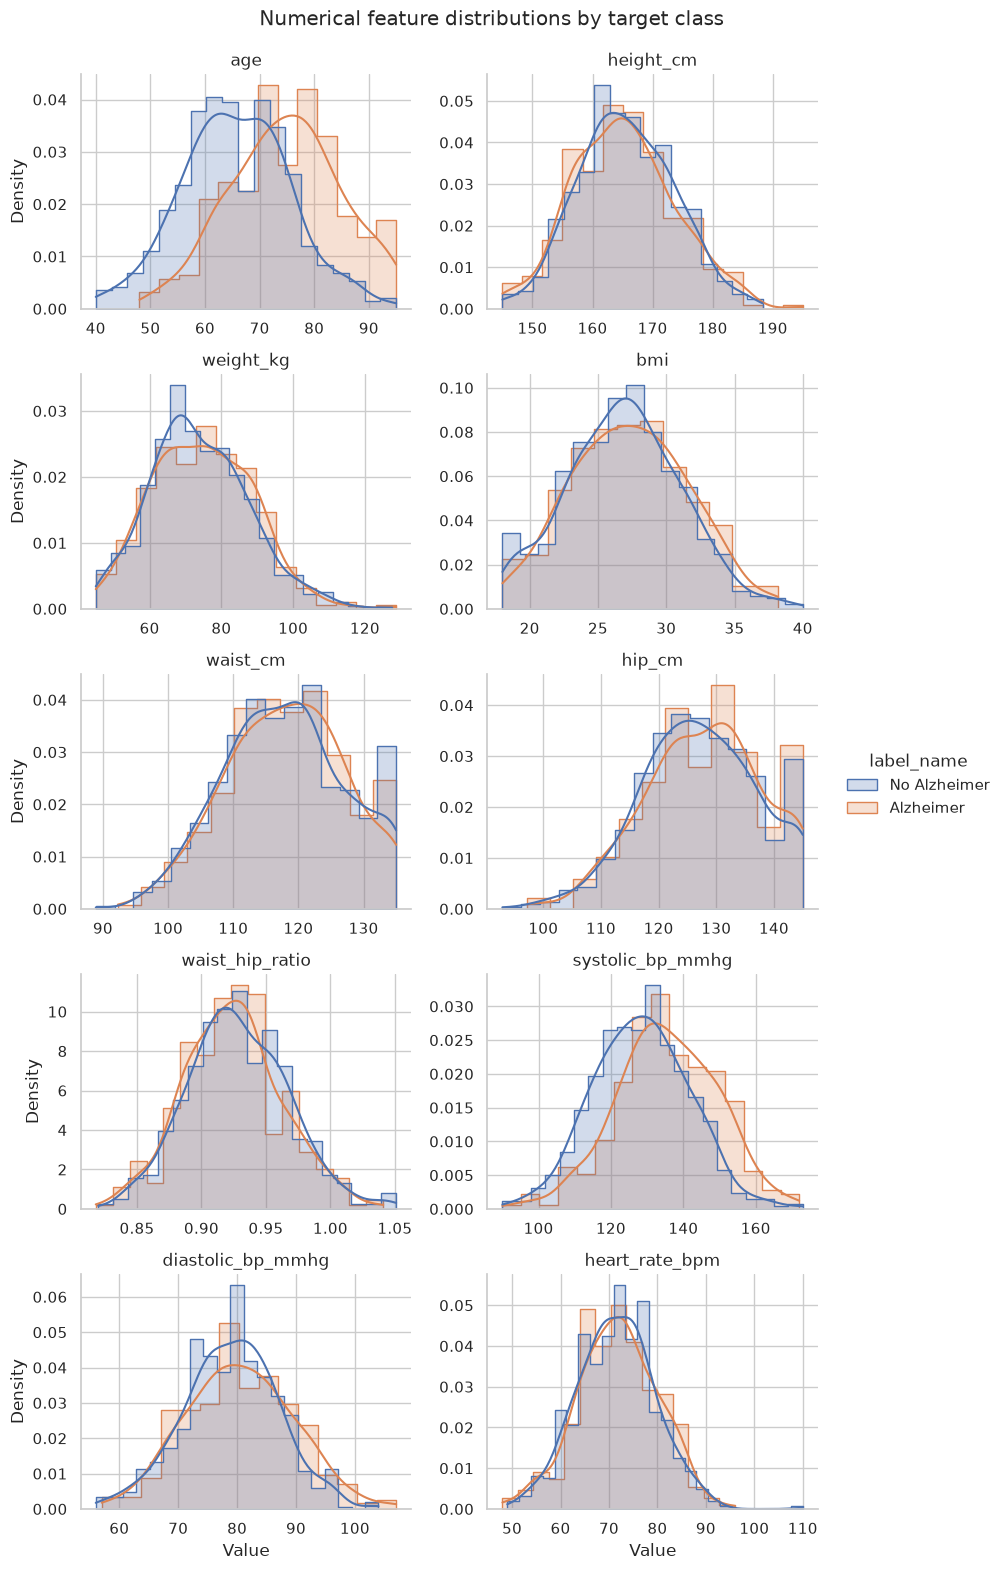

In [23]:
numeric_long = eda_df.melt(
    id_vars=["label_name"],
    value_vars=NUMERICAL_COLUMNS,
    var_name="feature",
    value_name="value",
)

g = sns.displot(
    data=numeric_long,
    x="value",
    hue="label_name",
    hue_order=LABEL_ORDER,
    col="feature",
    col_wrap=2,
    kind="hist",
    kde=True,
    stat="density",
    common_norm=False,
    common_bins=False,
    element="step",
    facet_kws={"sharex": False, "sharey": False},
    height=3.2,
    aspect=1.35,
)

g.set_axis_labels("Value", "Density")
g.set_titles("{col_name}")
g.fig.subplots_adjust(top=0.94)
g.fig.suptitle("Numerical feature distributions by target class")
g.fig.savefig(
    FIGURES_DIR / "03_numerical_distributions_by_label.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

## 10. Robust location and spread by class

Boxplots complement histograms by emphasizing the median, interquartile range, and potential extreme observations.

A boxplot does **not** prove that observations outside the whiskers are errors. It only marks values that are unusual relative to a conventional IQR rule.

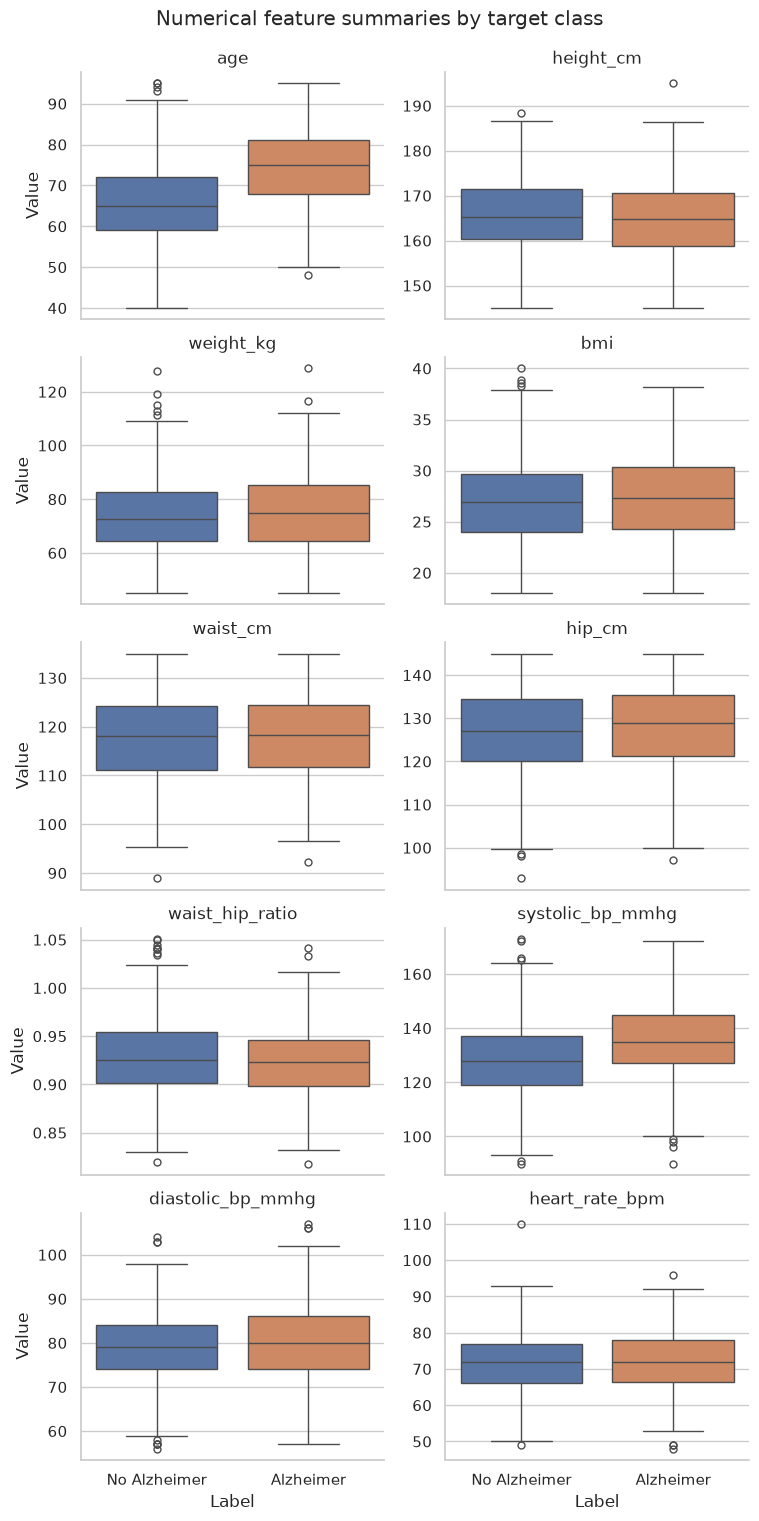

In [24]:
g = sns.catplot(
    data=numeric_long,
    x="label_name",
    y="value",
    hue="label_name",
    order=LABEL_ORDER,
    hue_order=LABEL_ORDER,
    legend=False,
    col="feature",
    col_wrap=2,
    kind="box",
    sharey=False,
    height=3.1,
    aspect=1.25,
)

g.set_axis_labels("Label", "Value")
g.set_titles("{col_name}")
g.fig.subplots_adjust(top=0.94)
g.fig.suptitle("Numerical feature summaries by target class")
g.fig.savefig(
    FIGURES_DIR / "04_numerical_boxplots_by_label.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

## 11. Categorical prevalence by class

The categorical predictors in this example are binary indicators coded as `0/1`.

For a binary feature, the mean of a `0/1` variable is the proportion of observations with value `1`. We therefore calculate the prevalence of each attribute **separately within each target class**.

For a feature \(X\), the table reports:

\[
P(X = 1 \mid \text{label}) \times 100
\]

The heatmap therefore answers:

> **Within each target class, what percentage of patients has each categorical attribute?**

This distinction is important. The two percentages in a row use **different denominators**: all patients in the `No Alzheimer` group and all patients in the `Alzheimer` group, respectively. Consequently, the values across a row **are not expected to sum to 100%**.

For example, if hypertension is reported as 26.6% for `No Alzheimer` and 49.6% for `Alzheimer`, this means that 26.6% of the first group and 49.6% of the second group have hypertension. It does **not** mean that the two values form complementary parts of the same population.

This is a descriptive comparison of group-specific prevalence. Formal statistical evidence and effect size are evaluated later.


In [25]:
categorical_prevalence_records = []

for feature in CATEGORICAL_COLUMNS:
    for target_value, label_name in LABEL_NAMES.items():
        values = eda_df.loc[eda_df[TARGET_COLUMN] == target_value, feature]

        categorical_prevalence_records.append(
            {
                "feature": feature,
                "label": target_value,
                "label_name": label_name,
                "n": int(values.notna().sum()),
                "count_positive": int((values == 1).sum()),
                "prevalence": values.mean(),
                "prevalence_percentage": 100 * values.mean(),
            }
        )

categorical_prevalence = pd.DataFrame(categorical_prevalence_records)
categorical_prevalence.to_csv(
    TABLES_DIR / "categorical_prevalence_by_label.csv",
    index=False,
)

prevalence_matrix = categorical_prevalence.pivot(
    index="feature",
    columns="label_name",
    values="prevalence_percentage",
).reindex(columns=LABEL_ORDER)

prevalence_matrix.index.name = "Binary feature"
prevalence_matrix.columns.name = None

prevalence_display = prevalence_matrix.rename(
    columns={
        label_name: f"{label_name} prevalence (%)"
        for label_name in LABEL_ORDER
    }
)

display(prevalence_display.round(1))

print(
    "Percentages are calculated within each label group; "
    "values across a row are not expected to sum to 100%."
)

,No Alzheimer prevalence (%),Alzheimer prevalence (%)
Binary feature,,
alcohol_risk,12.8,12.8
allergy_environmental,27.2,29.2
allergy_food,9.3,13.7
allergy_medication,18.6,14.0
asthma,15.4,14.9
cardiovascular_disease,12.9,20.4
chronic_kidney_disease,6.2,11.4
depression_history,15.2,23.6
diabetes_type2,11.0,24.8


Percentages are calculated within each label group; values across a row are not expected to sum to 100%.


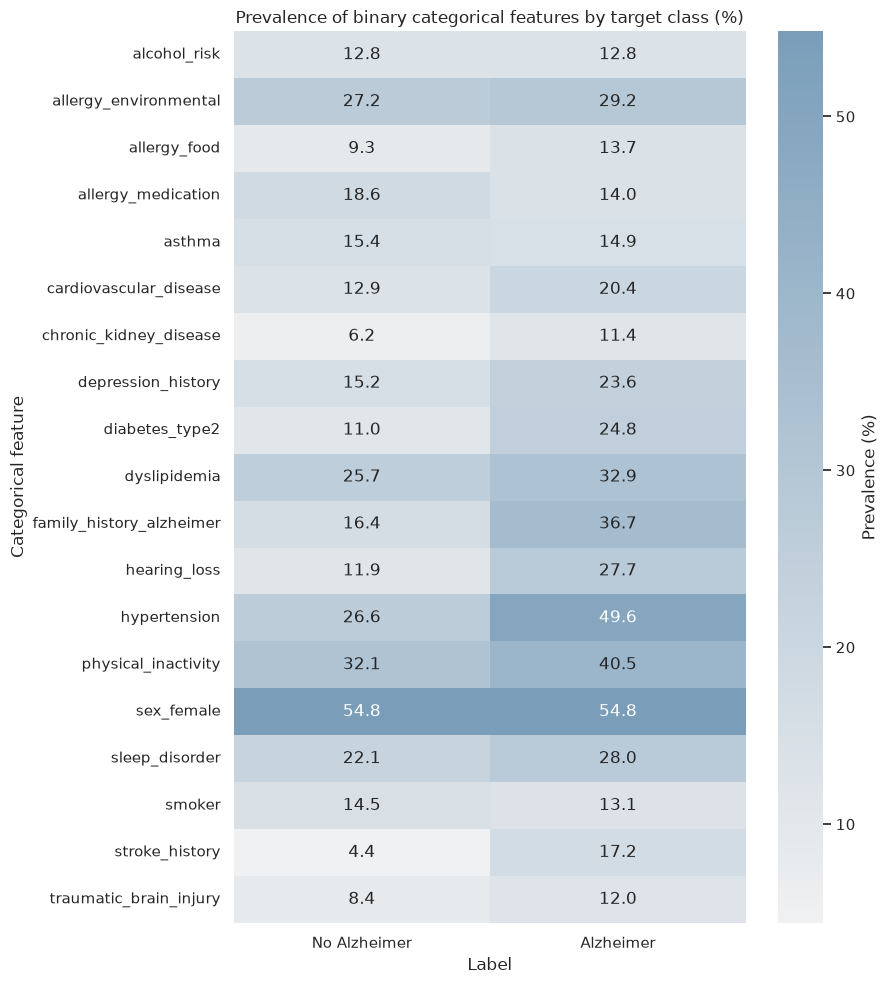

In [26]:
fig, ax = plt.subplots(figsize=(9, 10))

sns.heatmap(
    prevalence_matrix,
    annot=True,
    fmt=".1f",
    cmap=PASTEL_SEQUENTIAL_CMAP,
    cbar_kws={"label": "Prevalence (%)"},
    ax=ax,
)

ax.set(
    title="Prevalence of binary categorical features by target class (%)",
    xlabel="Label",
    ylabel="Categorical feature",
)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "05_categorical_prevalence_by_label.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

# Part III — Outlier diagnostics

## 12. Outliers should be examined within groups

A value that looks extreme in the complete dataset may be perfectly ordinary within one subgroup.

We therefore apply the conventional `1.5 × IQR` rule **separately within each target class**.

For a feature \(x\):

\[
IQR = Q_3 - Q_1
\]

and the conventional fences are:

\[
Q_1 - 1.5\,IQR
\qquad\text{and}\qquad
Q_3 + 1.5\,IQR
\]

Observations outside these fences are flagged for inspection.

> An outlier flag is a diagnostic signal, not an instruction to delete the observation.

In [27]:
outlier_records = []

for feature in NUMERICAL_COLUMNS:
    for target_value, label_name in LABEL_NAMES.items():
        values = eda_df.loc[eda_df[TARGET_COLUMN] == target_value, feature].dropna()

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1
        lower_fence = q1 - 1.5 * iqr
        upper_fence = q3 + 1.5 * iqr

        is_outlier = (values < lower_fence) | (values > upper_fence)

        outlier_records.append(
            {
                "feature": feature,
                "label": target_value,
                "label_name": label_name,
                "lower_fence": lower_fence,
                "upper_fence": upper_fence,
                "outlier_count": int(is_outlier.sum()),
                "outlier_percentage": 100 * is_outlier.mean(),
            }
        )

outlier_summary = pd.DataFrame(outlier_records)
outlier_summary.to_csv(TABLES_DIR / "outliers_iqr_by_label.csv", index=False)

outlier_matrix = outlier_summary.pivot(
    index="feature",
    columns="label_name",
    values="outlier_percentage",
).reindex(columns=LABEL_ORDER)

display(outlier_matrix.round(2))

label_name,No Alzheimer,Alzheimer
feature,,
age,0.61,0.29
bmi,0.61,0.00
diastolic_bp_mmhg,1.22,0.87
heart_rate_bpm,0.30,1.17
height_cm,0.15,0.29
hip_cm,0.46,0.29
systolic_bp_mmhg,0.91,1.17
waist_cm,0.15,0.29
waist_hip_ratio,1.37,0.87


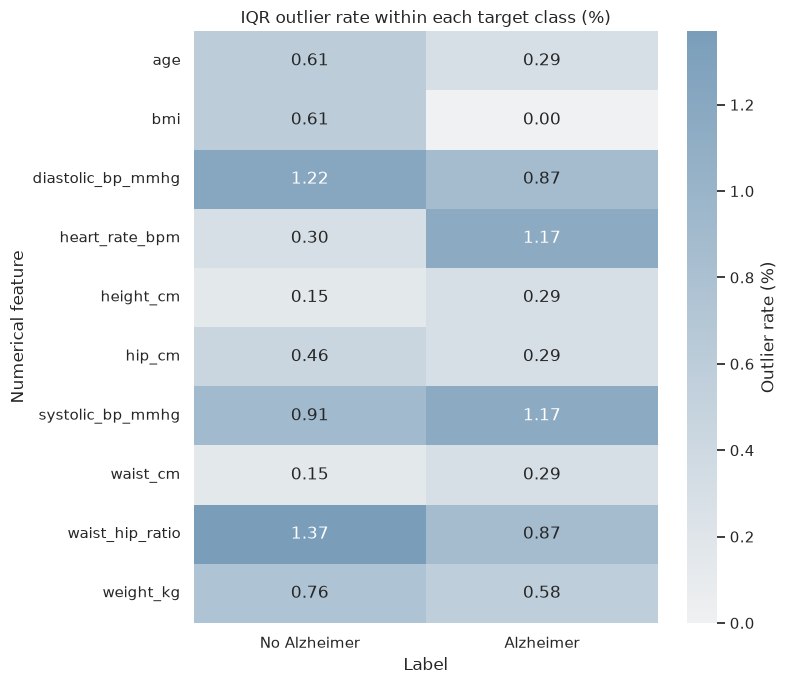

In [28]:
fig, ax = plt.subplots(figsize=(8, 7))

sns.heatmap(
    outlier_matrix,
    annot=True,
    fmt=".2f",
    cmap=PASTEL_SEQUENTIAL_CMAP,
    cbar_kws={"label": "Outlier rate (%)"},
    ax=ax,
)

ax.set(
    title="IQR outlier rate within each target class (%)",
    xlabel="Label",
    ylabel="Numerical feature",
)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "06_outlier_rate_by_label.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

# Part IV — Statistical comparison between label groups

## 13. Why p-values are not enough

A label-aware EDA often asks whether the distribution of a feature differs between groups.

For each numerical feature, this notebook reports two complementary tests:

- **Welch's t-test**, which compares group means without assuming equal variances;
- **Mann–Whitney U**, which is rank-based and does not require normality.

It also reports two effect sizes:

- **Hedges' g**, a standardized difference in means;
- **Cliff's delta**, a rank-based measure of distributional separation.

Because many features are tested, raw p-values are adjusted using the **Benjamini–Hochberg false discovery rate (FDR)**.

A small p-value answers a different question from a large effect size. Both should be reported.

In [29]:
def hedges_g(group_1: np.ndarray, group_0: np.ndarray) -> float:
    group_1 = np.asarray(group_1, dtype=float)
    group_0 = np.asarray(group_0, dtype=float)

    n1 = len(group_1)
    n0 = len(group_0)

    var1 = group_1.var(ddof=1)
    var0 = group_0.var(ddof=1)

    pooled_variance = (
        ((n1 - 1) * var1 + (n0 - 1) * var0)
        / (n1 + n0 - 2)
    )

    if pooled_variance <= 0:
        return np.nan

    cohen_d = (group_1.mean() - group_0.mean()) / np.sqrt(pooled_variance)

    degrees_freedom = n1 + n0 - 2
    correction = 1 - (3 / (4 * degrees_freedom - 1))

    return correction * cohen_d


def cliffs_delta_from_u(u_statistic: float, n1: int, n0: int) -> float:
    return (2 * u_statistic) / (n1 * n0) - 1


numerical_test_records = []

for feature in NUMERICAL_COLUMNS:
    group_0 = eda_df.loc[eda_df[TARGET_COLUMN] == 0, feature].dropna().to_numpy()
    group_1 = eda_df.loc[eda_df[TARGET_COLUMN] == 1, feature].dropna().to_numpy()

    welch = stats.ttest_ind(group_1, group_0, equal_var=False)
    mann_whitney = stats.mannwhitneyu(
        group_1,
        group_0,
        alternative="two-sided",
    )

    numerical_test_records.append(
        {
            "feature": feature,
            "mean_label_0": group_0.mean(),
            "mean_label_1": group_1.mean(),
            "mean_difference_1_minus_0": group_1.mean() - group_0.mean(),
            "welch_t": welch.statistic,
            "welch_p": welch.pvalue,
            "mann_whitney_u": mann_whitney.statistic,
            "mann_whitney_p": mann_whitney.pvalue,
            "hedges_g_1_minus_0": hedges_g(group_1, group_0),
            "cliffs_delta_1_minus_0": cliffs_delta_from_u(
                mann_whitney.statistic,
                len(group_1),
                len(group_0),
            ),
        }
    )

numerical_tests = pd.DataFrame(numerical_test_records)

numerical_tests["welch_q_fdr"] = multipletests(
    numerical_tests["welch_p"],
    method="fdr_bh",
)[1]

numerical_tests["mann_whitney_q_fdr"] = multipletests(
    numerical_tests["mann_whitney_p"],
    method="fdr_bh",
)[1]

numerical_tests["fdr_significant"] = (
    numerical_tests["mann_whitney_q_fdr"] < 0.05
)

numerical_tests = numerical_tests.sort_values(
    ["mann_whitney_q_fdr", "feature"]
).reset_index(drop=True)

numerical_tests.to_csv(
    TABLES_DIR / "numerical_label_comparisons.csv",
    index=False,
)

display(numerical_tests.round(5))

,feature,mean_label_0,mean_label_1,mean_difference_1_minus_0,welch_t,welch_p,mann_whitney_u,mann_whitney_p,hedges_g_1_minus_0,cliffs_delta_1_minus_0,welch_q_fdr,mann_whitney_q_fdr,fdr_significant
0,age,65.65449,74.79300,9.13851,13.57634,0.00000,166568.5,0.00000,0.90803,0.47830,0.00000,0.00000,True
1,systolic_bp_mmhg,128.39878,135.42857,7.02979,7.65008,0.00000,145478.5,0.00000,0.51704,0.29113,0.00000,0.00000,True
2,diastolic_bp_mmhg,78.95282,80.50729,1.55447,2.65683,0.00809,122934.5,0.01790,0.18373,0.09105,0.02697,0.05967,False
3,bmi,26.87260,27.33265,0.46005,1.62594,0.10442,119293.0,0.12695,0.10892,0.05873,0.20885,0.25391,False
4,waist_hip_ratio,0.92829,0.92407,-0.00422,-1.65494,0.09838,105936.5,0.12012,-0.10920,-0.05981,0.20885,0.25391,False
5,hip_cm,127.19680,128.02653,0.82973,1.23749,0.21632,118254.5,0.19817,0.08234,0.04951,0.36054,0.33029,False
6,weight_kg,73.90198,74.77114,0.86916,0.94464,0.34518,117178.0,0.29910,0.06310,0.03996,0.49311,0.42728,False
7,height_cm,165.62588,165.21691,-0.40897,-0.73515,0.46251,108642.0,0.35227,-0.04999,-0.03580,0.57814,0.44033,False
8,heart_rate_bpm,71.52055,71.79883,0.27829,0.50872,0.61111,115485.0,0.51675,0.03417,0.02493,0.67902,0.57417,False
9,waist_cm,117.96925,118.18746,0.21821,0.35814,0.72034,114982.5,0.59472,0.02362,0.02047,0.72034,0.59472,False


### Reading Cliff's delta

Cliff's delta ranges from `-1` to `1`.

- values near `0` indicate substantial overlap;
- positive values indicate that the feature tends to be larger in label `1`;
- negative values indicate that it tends to be larger in label `0`.

The magnitude, not only statistical significance, should be considered.

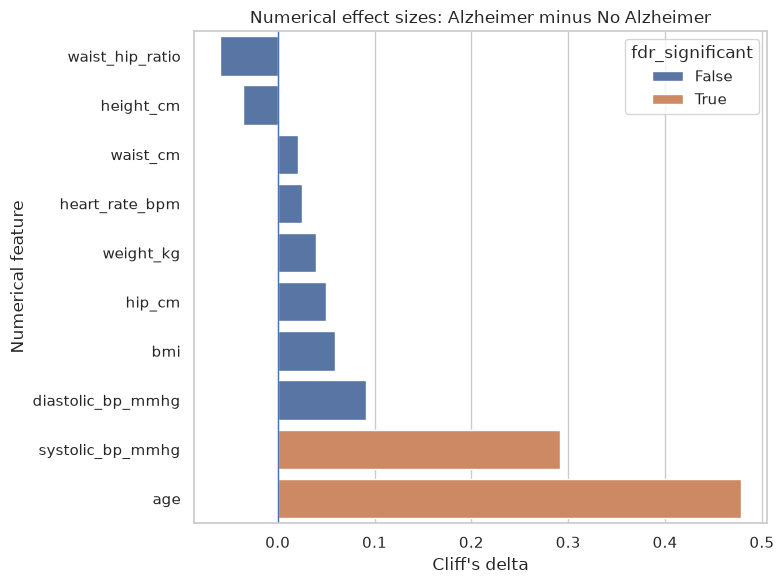

In [30]:
effect_plot_data = numerical_tests.sort_values(
    "cliffs_delta_1_minus_0"
).copy()

fig, ax = plt.subplots(figsize=(8, 6))

sns.barplot(
    data=effect_plot_data,
    x="cliffs_delta_1_minus_0",
    y="feature",
    hue="fdr_significant",
    ax=ax,
)

ax.axvline(0, linewidth=1)
ax.set(
    title="Numerical effect sizes: Alzheimer minus No Alzheimer",
    xlabel="Cliff's delta",
    ylabel="Numerical feature",
)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "07_numerical_effect_sizes.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

## 14. Association between binary categorical features and the label

For each binary categorical predictor, we construct a `2 × 2` contingency table against the binary target.

The notebook uses:

- Pearson's **chi-square test** when expected cell counts are sufficiently large;
- **Fisher's exact test** when at least one expected count is below 5;
- **Cramér's V** as an association effect size;
- an **odds ratio** as an interpretable directional measure.

All test p-values are corrected together with Benjamini–Hochberg FDR.

In [31]:
def cramers_v_from_table(table: pd.DataFrame) -> float:
    chi2, _, _, _ = stats.chi2_contingency(table, correction=False)
    n = table.to_numpy().sum()
    min_dimension = min(table.shape) - 1

    if n == 0 or min_dimension == 0:
        return np.nan

    return np.sqrt((chi2 / n) / min_dimension)


categorical_test_records = []

for feature in CATEGORICAL_COLUMNS:
    table = pd.crosstab(
        eda_df[feature],
        eda_df[TARGET_COLUMN],
    ).reindex(index=[0, 1], columns=[0, 1], fill_value=0)

    chi2, chi_p, _, expected = stats.chi2_contingency(table)

    if (expected < 5).any():
        odds_ratio, p_value = stats.fisher_exact(table.to_numpy())
        test_name = "Fisher exact"
    else:
        odds_ratio, _ = stats.fisher_exact(table.to_numpy())
        p_value = chi_p
        test_name = "Chi-square"

    prevalence_0 = eda_df.loc[eda_df[TARGET_COLUMN] == 0, feature].mean()
    prevalence_1 = eda_df.loc[eda_df[TARGET_COLUMN] == 1, feature].mean()

    categorical_test_records.append(
        {
            "feature": feature,
            "test": test_name,
            "prevalence_label_0": prevalence_0,
            "prevalence_label_1": prevalence_1,
            "prevalence_difference_1_minus_0": prevalence_1 - prevalence_0,
            "odds_ratio": odds_ratio,
            "cramers_v": cramers_v_from_table(table),
            "p_value": p_value,
        }
    )

categorical_tests = pd.DataFrame(categorical_test_records)

categorical_tests["q_fdr"] = multipletests(
    categorical_tests["p_value"],
    method="fdr_bh",
)[1]

categorical_tests["fdr_significant"] = categorical_tests["q_fdr"] < 0.05

categorical_tests = categorical_tests.sort_values(
    ["q_fdr", "feature"]
).reset_index(drop=True)

categorical_tests.to_csv(
    TABLES_DIR / "categorical_label_associations.csv",
    index=False,
)

display(categorical_tests.round(5))

,feature,test,prevalence_label_0,prevalence_label_1,prevalence_difference_1_minus_0,odds_ratio,cramers_v,p_value,q_fdr,fdr_significant
0,family_history_alzheimer,Chi-square,0.16438,0.36735,0.20296,2.95161,0.22758,0.00000,0.00000,True
1,hypertension,Chi-square,0.26636,0.49563,0.22926,2.70652,0.22895,0.00000,0.00000,True
2,stroke_history,Chi-square,0.04414,0.17201,0.12787,4.49879,0.21427,0.00000,0.00000,True
3,hearing_loss,Chi-square,0.11872,0.27697,0.15825,2.84352,0.19860,0.00000,0.00000,True
4,diabetes_type2,Chi-square,0.10959,0.24781,0.13822,2.67684,0.18036,0.00000,0.00000,True
5,depression_history,Chi-square,0.15221,0.23615,0.08394,1.72202,0.10350,0.00144,0.00456,True
6,cardiovascular_disease,Chi-square,0.12938,0.20408,0.07471,1.72549,0.09799,0.00264,0.00717,True
7,chronic_kidney_disease,Chi-square,0.06240,0.11370,0.05130,1.92747,0.08976,0.00661,0.01571,True
8,physical_inactivity,Chi-square,0.32116,0.40525,0.08409,1.44025,0.08369,0.00997,0.02105,True
9,dyslipidemia,Chi-square,0.25723,0.32945,0.07222,1.41868,0.07619,0.01953,0.03711,True


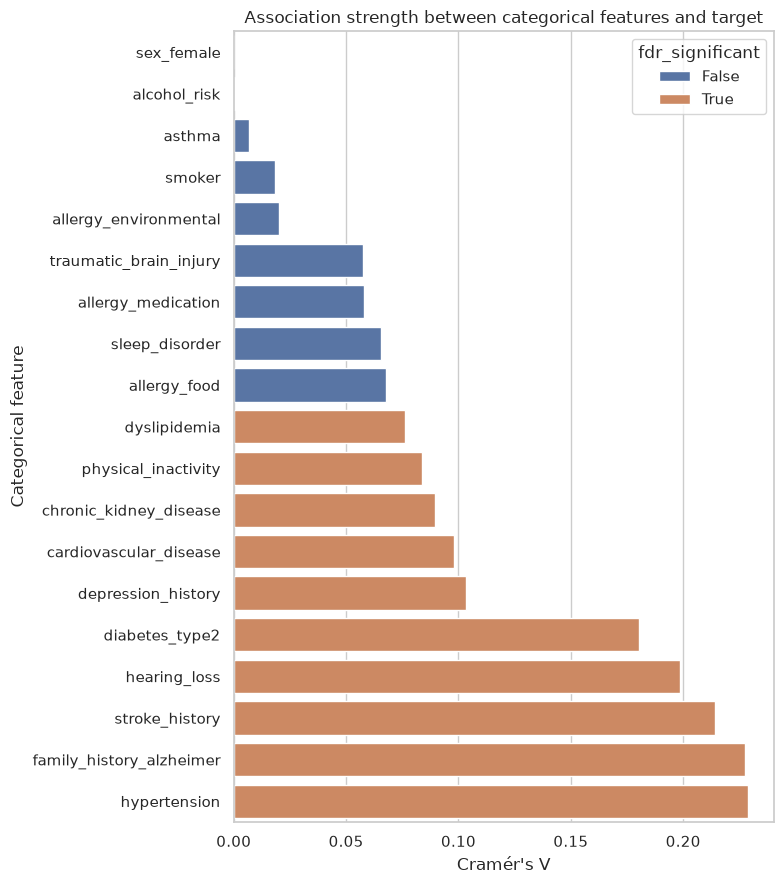

In [32]:
categorical_effect_plot = categorical_tests.sort_values(
    "cramers_v"
).copy()

fig, ax = plt.subplots(figsize=(8, 9))

sns.barplot(
    data=categorical_effect_plot,
    x="cramers_v",
    y="feature",
    hue="fdr_significant",
    ax=ax,
)

ax.set(
    title="Association strength between categorical features and target",
    xlabel="Cramér's V",
    ylabel="Categorical feature",
)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "08_categorical_association_effect_sizes.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

# Part V — Bivariate relationships

## 15. Numerical–numerical relationships with the label visible

A scatterplot asks whether two numerical variables change together.

Adding the label as hue allows us to inspect:

- whether the classes occupy similar regions;
- whether a relationship is shared by both groups;
- whether one class appears shifted;
- whether apparent clusters are explained by the target.

A full pairplot becomes unreadable when too many variables are included, so a small, predefined subset is used for teaching.

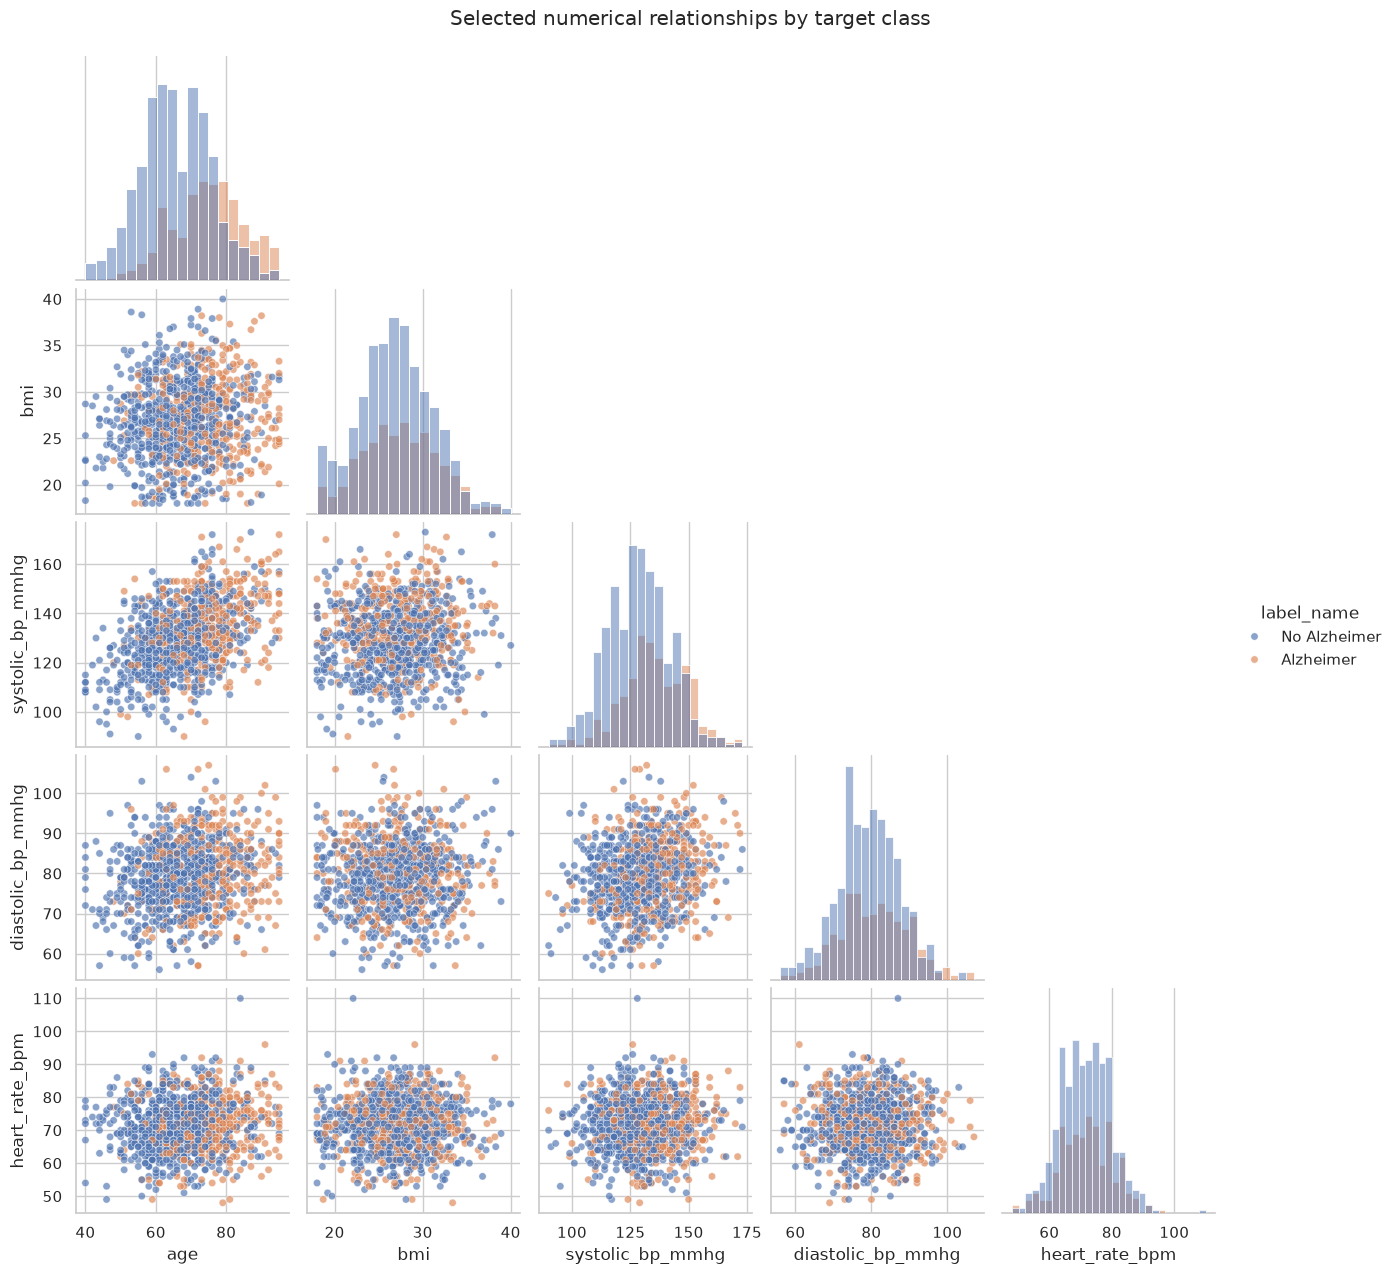

In [33]:
PAIRPLOT_FEATURES = [
    "age",
    "bmi",
    "systolic_bp_mmhg",
    "diastolic_bp_mmhg",
    "heart_rate_bpm",
]

pairplot_data = eda_df[PAIRPLOT_FEATURES + ["label_name"]].copy()

g = sns.pairplot(
    pairplot_data,
    vars=PAIRPLOT_FEATURES,
    hue="label_name",
    hue_order=LABEL_ORDER,
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.65, "s": 28},
)

g.fig.suptitle(
    "Selected numerical relationships by target class",
    y=1.02,
)
g.fig.savefig(
    FIGURES_DIR / "09_pairplot_selected_numerical_features.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

## 16. Correlation is not one universal property of the dataset

A single correlation matrix can hide class-specific structure.

We therefore calculate **Spearman correlations separately within each label group**. Spearman correlation is rank-based and is less dependent on linearity and Gaussian distributions than Pearson correlation.

The label is not numerically included in these matrices. Instead, it defines the groups whose internal relationships are compared.

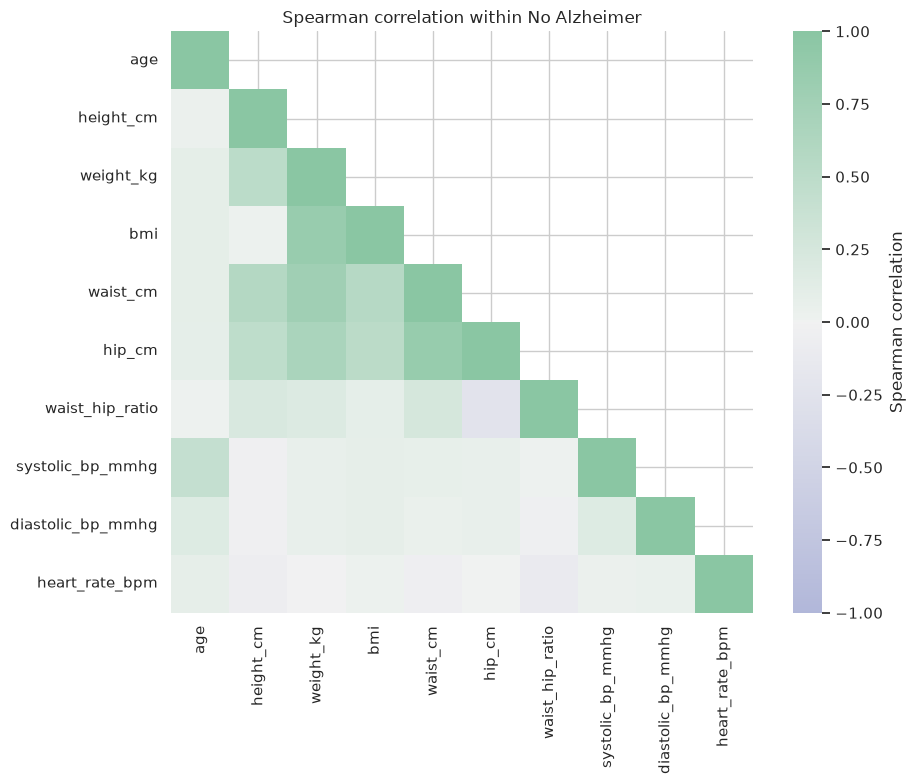

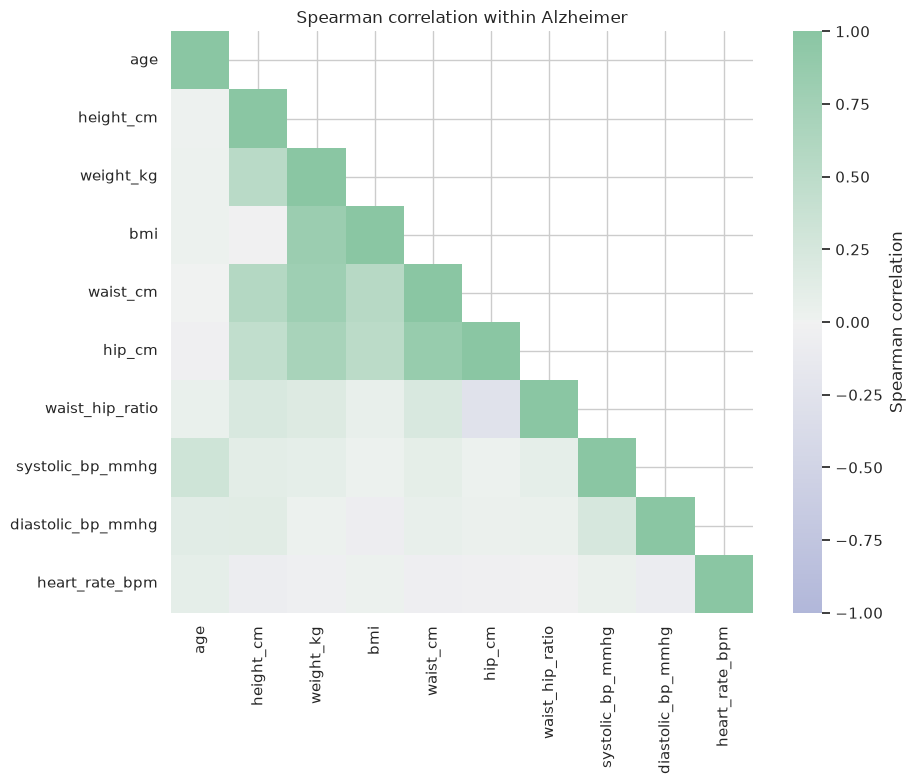

In [34]:
correlation_by_label = {}

for target_value, label_name in LABEL_NAMES.items():
    subset = eda_df.loc[
        eda_df[TARGET_COLUMN] == target_value,
        NUMERICAL_COLUMNS,
    ]

    correlation = subset.corr(method="spearman")
    correlation_by_label[target_value] = correlation

    correlation.to_csv(
        TABLES_DIR / f"spearman_correlations_label_{target_value}.csv"
    )

    mask = np.triu(np.ones_like(correlation, dtype=bool), k=1)

    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(
        correlation,
        mask=mask,
        vmin=-1,
        vmax=1,
        center=0,
        cmap=PASTEL_DIVERGING_CMAP,
        square=True,
        cbar_kws={"label": "Spearman correlation"},
        ax=ax,
    )
    ax.set_title(f"Spearman correlation within {label_name}")
    fig.tight_layout()
    fig.savefig(
        FIGURES_DIR / f"10_spearman_correlation_label_{target_value}.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()

### Correlation differences between classes

The next matrix subtracts the correlation matrix of label `0` from that of label `1`.

A large difference means that a pair of variables has a different rank-correlation structure across classes.

This is exploratory evidence only. A difference between two sample correlations is not automatically statistically significant.

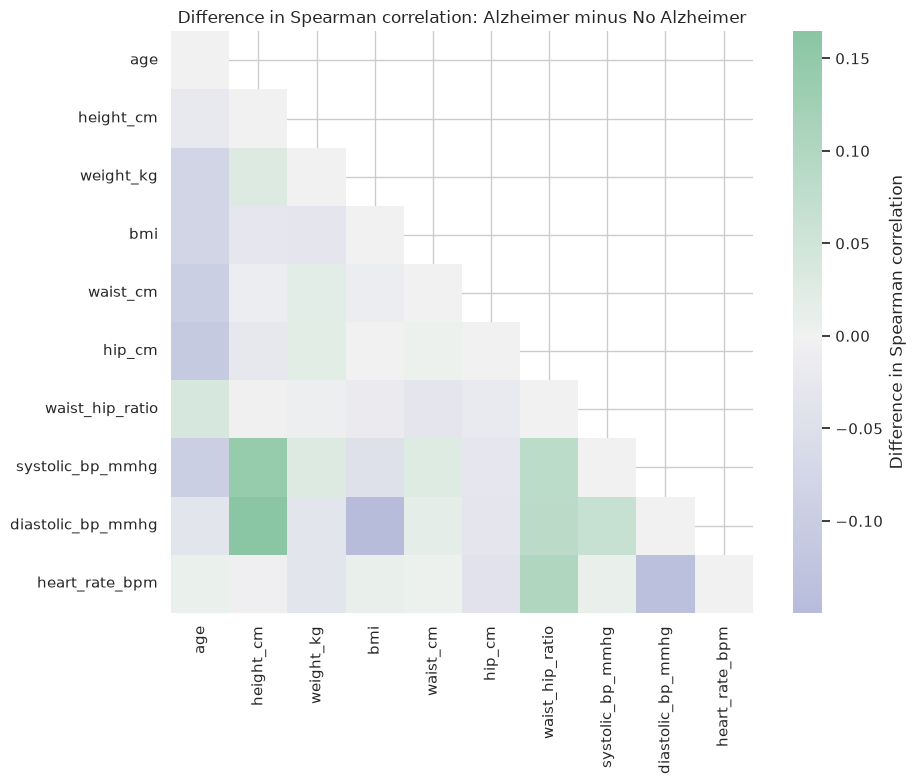

In [35]:
correlation_difference = (
    correlation_by_label[1] - correlation_by_label[0]
)

correlation_difference.to_csv(
    TABLES_DIR / "spearman_correlation_difference_1_minus_0.csv"
)

mask = np.triu(
    np.ones_like(correlation_difference, dtype=bool),
    k=1,
)

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    correlation_difference,
    mask=mask,
    center=0,
    cmap=PASTEL_DIVERGING_CMAP,
    square=True,
    cbar_kws={"label": "Difference in Spearman correlation"},
    ax=ax,
)

ax.set_title(
    "Difference in Spearman correlation: Alzheimer minus No Alzheimer"
)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "11_spearman_correlation_difference.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

# Part VI — Multivariable structure

## 17. Principal Component Analysis

PCA transforms correlated numerical variables into orthogonal linear combinations called **principal components**.

Before PCA, numerical features are standardized because they are measured in different units. Without scaling, variables with larger numerical variance could dominate the projection.

Two principles are essential:

1. the **target label is not used to fit PCA**;
2. the label is added only afterward to visualize whether known classes occupy different regions of the unsupervised projection.

PCA is useful for geometry and dimensionality reduction. It is not a classifier, and visible overlap or separation is not a measure of predictive performance.

In [36]:
X_numeric = eda_df[NUMERICAL_COLUMNS].copy()

numeric_scaler = StandardScaler()
X_numeric_scaled = numeric_scaler.fit_transform(X_numeric)

pca = PCA()
pca_scores = pca.fit_transform(X_numeric_scaled)

pca_variance = pd.DataFrame(
    {
        "component": np.arange(1, len(NUMERICAL_COLUMNS) + 1),
        "explained_variance_ratio": pca.explained_variance_ratio_,
        "cumulative_explained_variance": np.cumsum(
            pca.explained_variance_ratio_
        ),
    }
)

pca_variance.to_csv(
    TABLES_DIR / "pca_explained_variance.csv",
    index=False,
)

display(pca_variance.round(4))

,component,explained_variance_ratio,cumulative_explained_variance
0,1,0.3459,0.3459
1,2,0.1576,0.5036
2,3,0.1239,0.6275
3,4,0.1057,0.7331
4,5,0.0953,0.8285
5,6,0.0849,0.9134
6,7,0.0539,0.9672
7,8,0.0323,0.9995
8,9,0.0004,0.9999
9,10,0.0001,1.0000


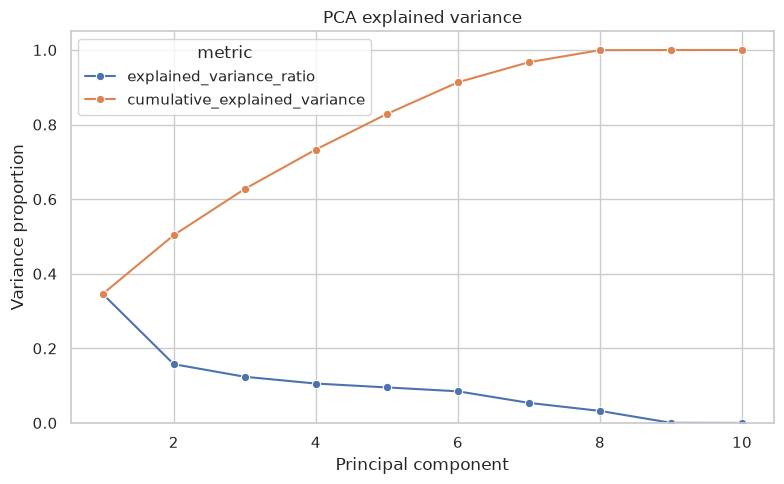

In [37]:
pca_variance_long = pca_variance.melt(
    id_vars="component",
    value_vars=[
        "explained_variance_ratio",
        "cumulative_explained_variance",
    ],
    var_name="metric",
    value_name="value",
)

fig, ax = plt.subplots(figsize=(8, 5))

sns.lineplot(
    data=pca_variance_long,
    x="component",
    y="value",
    hue="metric",
    marker="o",
    ax=ax,
)

ax.set(
    title="PCA explained variance",
    xlabel="Principal component",
    ylabel="Variance proportion",
    ylim=(0, 1.05),
)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "12_pca_explained_variance.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

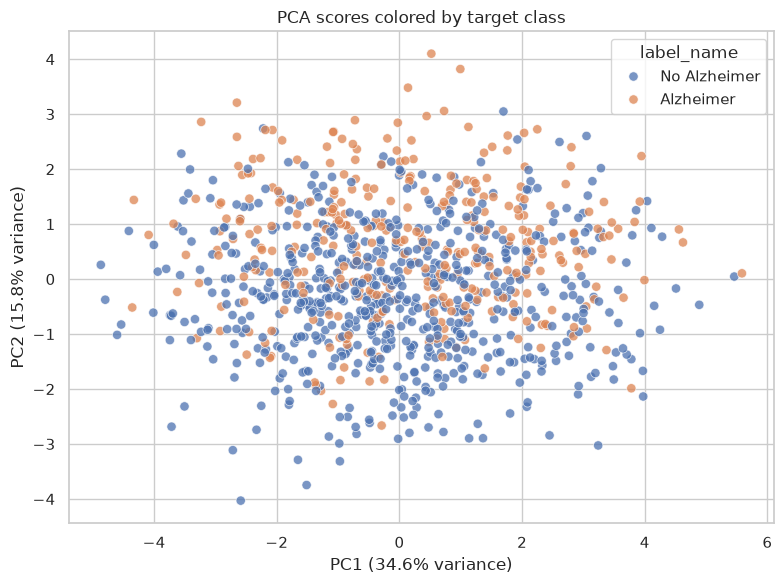

In [38]:
pca_score_df = pd.DataFrame(
    {
        "PC1": pca_scores[:, 0],
        "PC2": pca_scores[:, 1],
        "label_name": eda_df["label_name"].to_numpy(),
    }
)

pc1_variance = 100 * pca.explained_variance_ratio_[0]
pc2_variance = 100 * pca.explained_variance_ratio_[1]

fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    data=pca_score_df,
    x="PC1",
    y="PC2",
    hue="label_name",
    hue_order=LABEL_ORDER,
    alpha=0.75,
    s=45,
    ax=ax,
)

ax.set(
    title="PCA scores colored by target class",
    xlabel=f"PC1 ({pc1_variance:.1f}% variance)",
    ylabel=f"PC2 ({pc2_variance:.1f}% variance)",
)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "13_pca_scores_by_label.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

## 18. PCA loadings

Scores describe observations. **Loadings** describe how the original variables contribute to each principal component.

A projection should not be interpreted only from the position of points. Inspecting loadings helps explain which variables define the axes being visualized.

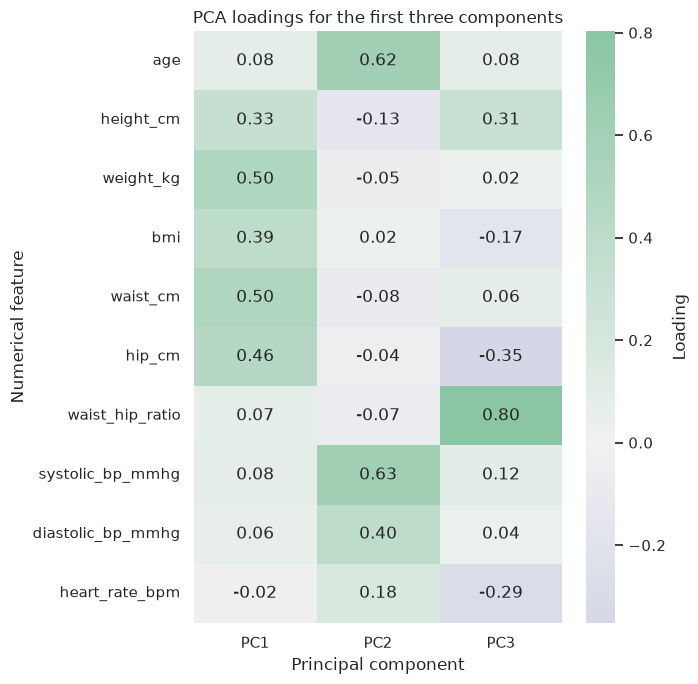

In [39]:
pca_loadings = pd.DataFrame(
    pca.components_[:3].T,
    index=NUMERICAL_COLUMNS,
    columns=["PC1", "PC2", "PC3"],
)

pca_loadings.to_csv(TABLES_DIR / "pca_loadings_first_3_components.csv")

fig, ax = plt.subplots(figsize=(7, 7))

sns.heatmap(
    pca_loadings,
    annot=True,
    fmt=".2f",
    center=0,
    cmap=PASTEL_DIVERGING_CMAP,
    cbar_kws={"label": "Loading"},
    ax=ax,
)

ax.set(
    title="PCA loadings for the first three components",
    xlabel="Principal component",
    ylabel="Numerical feature",
)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "14_pca_loadings.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

# Part VII — Nonlinear projections

## 19. Prepare a mixed feature matrix

For nonlinear projections, we use all predictors:

- numerical variables are standardized;
- binary categorical variables remain encoded as `0/1`;
- the identifier and target are excluded.

This matrix represents the predictor space only.

The label will again be added **after projection** for visualization.

In [40]:
feature_preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", StandardScaler(), NUMERICAL_COLUMNS),
        ("categorical", "passthrough", CATEGORICAL_COLUMNS),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

X_projection = feature_preprocessor.fit_transform(eda_df)

print("Projection matrix shape:", X_projection.shape)
print("Target included in projection matrix:", TARGET_COLUMN in NUMERICAL_COLUMNS + CATEGORICAL_COLUMNS)

Projection matrix shape: (1000, 29)
Target included in projection matrix: False


## 20. t-SNE

t-SNE is a nonlinear projection designed primarily to preserve **local neighborhoods**.

Important interpretation rules:

- nearby points can be meaningfully similar in the projected space;
- distances between distant clusters are much less reliable;
- cluster size and spacing can be distorted;
- different random seeds or hyperparameters can change the map;
- visible class separation is not predictive validation.

The target label is used only to color the final two-dimensional projection.

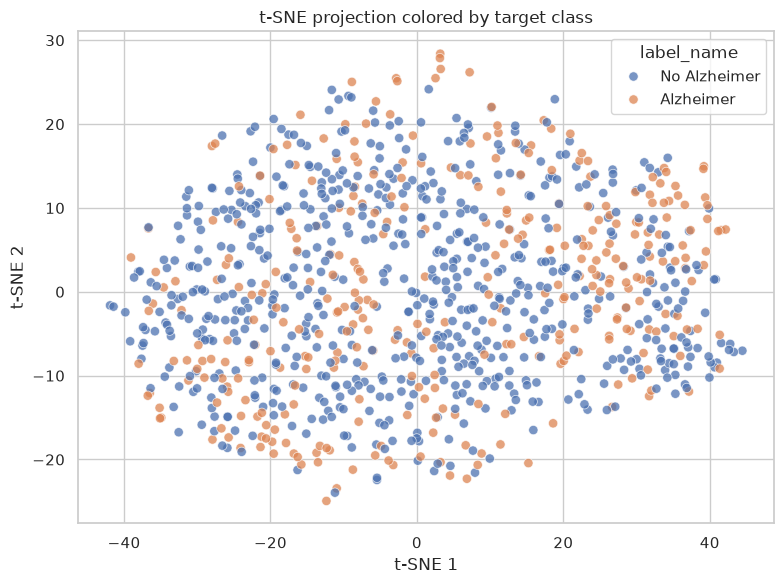

In [41]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=RANDOM_STATE,
)

tsne_coordinates = tsne.fit_transform(X_projection)

tsne_df = pd.DataFrame(
    {
        "tSNE1": tsne_coordinates[:, 0],
        "tSNE2": tsne_coordinates[:, 1],
        "label_name": eda_df["label_name"].to_numpy(),
    }
)

tsne_df.to_csv(TABLES_DIR / "tsne_coordinates.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    data=tsne_df,
    x="tSNE1",
    y="tSNE2",
    hue="label_name",
    hue_order=LABEL_ORDER,
    alpha=0.75,
    s=45,
    ax=ax,
)

ax.set(
    title="t-SNE projection colored by target class",
    xlabel="t-SNE 1",
    ylabel="t-SNE 2",
)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "15_tsne_by_label.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

## 21. UMAP

UMAP is another nonlinear manifold-learning method. It is often useful for visualizing local neighborhoods while preserving more large-scale organization than t-SNE, although the result still depends on hyperparameters and stochastic optimization.

This section is optional because UMAP is provided by the separate `umap-learn` package.

If it is not installed:

```bash
python -m pip install umap-learn
```

As with PCA and t-SNE, the target label is **not used to construct the projection**.

/home/david/miniconda3/envs/ml2026/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


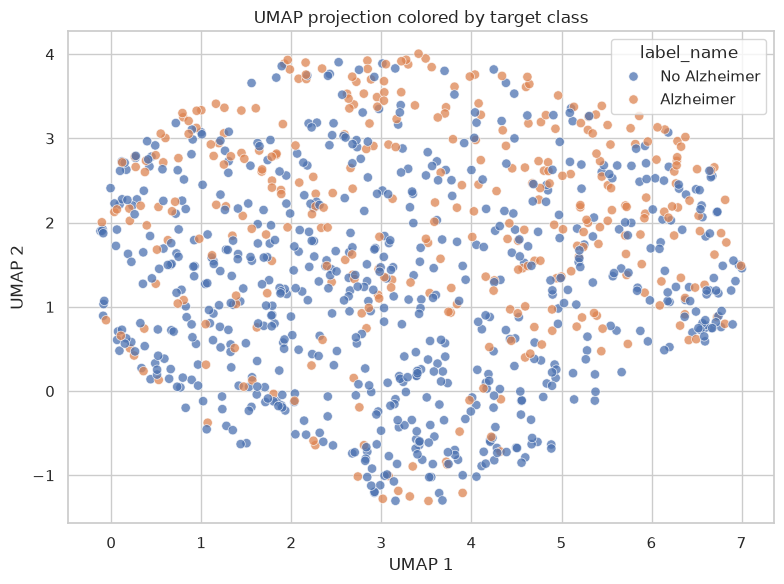

In [42]:
if UMAP_AVAILABLE:
    umap_model = umap.UMAP(
        n_components=2,
        n_neighbors=15,
        min_dist=0.1,
        random_state=RANDOM_STATE,
    )

    umap_coordinates = umap_model.fit_transform(X_projection)

    umap_df = pd.DataFrame(
        {
            "UMAP1": umap_coordinates[:, 0],
            "UMAP2": umap_coordinates[:, 1],
            "label_name": eda_df["label_name"].to_numpy(),
        }
    )

    umap_df.to_csv(TABLES_DIR / "umap_coordinates.csv", index=False)

    fig, ax = plt.subplots(figsize=(8, 6))

    sns.scatterplot(
        data=umap_df,
        x="UMAP1",
        y="UMAP2",
        hue="label_name",
        hue_order=LABEL_ORDER,
        alpha=0.75,
        s=45,
        ax=ax,
    )

    ax.set(
        title="UMAP projection colored by target class",
        xlabel="UMAP 1",
        ylabel="UMAP 2",
    )

    fig.tight_layout()
    fig.savefig(
        FIGURES_DIR / "16_umap_by_label.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
else:
    print(
        "UMAP section skipped because 'umap-learn' is not installed. "
        "Install it with: python -m pip install umap-learn"
    )

# Part VIII — Consolidated exploratory summary

## 22. Rank the strongest label-associated patterns

EDA should end by consolidating what was observed rather than leaving dozens of unrelated plots.

The following tables rank:

- numerical features by absolute Cliff's delta;
- categorical features by Cramér's V.

These rankings summarize **observed group differences in this dataset**. They are not a feature-selection procedure and must not be interpreted as model importance.

In [43]:
top_numerical = (
    numerical_tests.assign(
        absolute_cliffs_delta=lambda x: x["cliffs_delta_1_minus_0"].abs()
    )
    .sort_values(
        ["absolute_cliffs_delta", "mann_whitney_q_fdr"],
        ascending=[False, True],
    )
    [
        [
            "feature",
            "mean_difference_1_minus_0",
            "cliffs_delta_1_minus_0",
            "mann_whitney_q_fdr",
            "fdr_significant",
        ]
    ]
    .reset_index(drop=True)
)

top_categorical = (
    categorical_tests.sort_values(
        ["cramers_v", "q_fdr"],
        ascending=[False, True],
    )
    [
        [
            "feature",
            "prevalence_difference_1_minus_0",
            "cramers_v",
            "odds_ratio",
            "q_fdr",
            "fdr_significant",
        ]
    ]
    .reset_index(drop=True)
)

print("Numerical features ranked by absolute Cliff's delta")
display(top_numerical.round(5))

print("Categorical features ranked by Cramér's V")
display(top_categorical.round(5))

Numerical features ranked by absolute Cliff's delta


,feature,mean_difference_1_minus_0,cliffs_delta_1_minus_0,mann_whitney_q_fdr,fdr_significant
0,age,9.13851,0.47830,0.00000,True
1,systolic_bp_mmhg,7.02979,0.29113,0.00000,True
2,diastolic_bp_mmhg,1.55447,0.09105,0.05967,False
3,waist_hip_ratio,-0.00422,-0.05981,0.25391,False
4,bmi,0.46005,0.05873,0.25391,False
5,hip_cm,0.82973,0.04951,0.33029,False
6,weight_kg,0.86916,0.03996,0.42728,False
7,height_cm,-0.40897,-0.03580,0.44033,False
8,heart_rate_bpm,0.27829,0.02493,0.57417,False
9,waist_cm,0.21821,0.02047,0.59472,False


Categorical features ranked by Cramér's V


,feature,prevalence_difference_1_minus_0,cramers_v,odds_ratio,q_fdr,fdr_significant
0,hypertension,0.22926,0.22895,2.70652,0.00000,True
1,family_history_alzheimer,0.20296,0.22758,2.95161,0.00000,True
2,stroke_history,0.12787,0.21427,4.49879,0.00000,True
3,hearing_loss,0.15825,0.19860,2.84352,0.00000,True
4,diabetes_type2,0.13822,0.18036,2.67684,0.00000,True
5,depression_history,0.08394,0.10350,1.72202,0.00456,True
6,cardiovascular_disease,0.07471,0.09799,1.72549,0.00717,True
7,chronic_kidney_disease,0.05130,0.08976,1.92747,0.01571,True
8,physical_inactivity,0.08409,0.08369,1.44025,0.02105,True
9,dyslipidemia,0.07222,0.07619,1.41868,0.03711,True


## 23. What this EDA does and does not establish

This notebook has now examined the dataset at several complementary levels:

- **dataset level:** shape, roles, missingness, class balance;
- **univariate:** distributions and robust summaries by label;
- **outliers:** label-specific IQR diagnostics;
- **statistical comparison:** tests, FDR correction, and effect sizes;
- **bivariate:** pairwise relationships and class-specific correlations;
- **multivariate:** PCA scores and loadings;
- **nonlinear geometry:** t-SNE and optional UMAP.

The analysis can reveal candidate patterns worth investigating. It does **not** establish that:

- a variable causes Alzheimer status;
- an association will generalize to unseen data;
- an EDA effect size is equivalent to predictive importance;
- visible separation in PCA, t-SNE, or UMAP implies high classification performance;
- a statistically significant result is automatically biologically or clinically important.

### Leakage warning for later modelling

Once a train/test split is created, the test set should no longer be used for exploratory decisions that influence the model. Feature selection, thresholds, transformations, or modelling choices motivated by the label must be learned from training data and evaluated on untouched data.

The next stage should therefore treat this EDA as **dataset understanding**, not as a substitute for a properly validated machine-learning workflow.

## 24. Outputs produced by this notebook

The notebook exports reproducible artifacts under:

```text
results/synthetic_alzheimer/eda_categorical/
```

The `tables/` folder contains the numerical summaries, statistical tests, effect sizes, correlations, PCA results, and projection coordinates.

The `figures/` folder contains the Seaborn-based visualizations generated during the EDA.

Keeping these outputs separate from the processed dataset preserves a simple principle:

```text
processed data  ->  analysis  ->  results
```

The processed dataset remains an input to the analysis and is never silently modified by the EDA.